# Демонстрация PSI в DigitQt

Тетрадка делает то же, что `psi_demo.py`, но параметры задаются **здесь, в ячейке ниже**:

1. генерирует серию кадров $I_n = A + B\cos\bigl(\varphi + \delta_n(x,y)\bigr)$ с заданными сдвигами, наклонами, фронтом, шумом;
2. прогоняет её через **настоящий** конвейер DigitQt (`tools/psi_check`: S2 PSI → S4 → S5) в нескольких режимах;
3. сравнивает найденные сдвиги, наклоны и карту с заложенными.

**Как работать:** выбери сценарий или поправь числа в ячейке «Параметры» → *Run All*.

Нужен собранный `psi_check` (CMake с `-DDIGITQT_BUILD_TOOLS=ON`, папка `build-tests`), numpy и matplotlib.

## Параметры

`SCENARIO` — готовый набор из `PRESETS` (ячейка ниже), `OVERRIDES` — что поменять поверх него.
Пустой `OVERRIDES` — сценарий как есть.

| параметр | единицы | смысл |
|---|---|---|
| `shifts` | град | настоящие сдвиги кадров, по одному на кадр (не меньше 3) |
| `tilt_x`, `tilt_y` | волн на кадр | наклон сдвига каждого кадра (`None` — без наклона) |
| `step` | град | номинальный шаг, который «знает» DigitQt |
| `carrier_x`, `carrier_y` | волн | несущая — наклон эталона: $u$, $-v$ |
| `defocus` | волн | $u^2+v^2$ |
| `astig_x`, `astig_y` | волн | астигматизм: $1.5(u^2-v^2)$, $-uv$ |
| `coma_x`, `coma_y` | волн | кома: $u^3+uv^2-\tfrac23u$, $\tfrac23v-v(u^2+v^2)$ |
| `trefoil_x`, `trefoil_y` | волн | трилистник: $3uv^2-u^3$, $3u^2v-v^3$ |
| `spherical` | волн | сферическая: $(u^2+v^2)^2$ |
| `noise` | уровни яркости | шум камеры |
| `beam` | — | гауссов пучок, 0.5 на краю апертуры |
| `a`, `b` | уровни | фон и амплитуда полос |
| `size` | px | размер кадра |
| `modes` | — | `nominal` — без уточнения, `refine` — уточнение сдвигов, `tilt` — плюс наклон |

Фронт задаётся коэффициентами при полиномах **базиса Серегина** — тех же, что раскладывает S5 DigitQt ($u$ вправо, $v$ вниз, обе в $[-1,1]$ по апертуре). Поэтому S5 должен вернуть ровно заложенные числа — это проверка всей цепочки S2 → S4 → S5.

In [17]:
PRESETS = {
    # Неравные сдвиги рис. 4 статьи: уточнение против номинальных 90.
    "article": dict(shifts=[0, 72, 198, 266.4, 36]),
    # Идеальный шаг 90: все режимы одинаково хороши.
    "ideal": dict(shifts=[0, 90, 180, 270]),
    # Наклон между кадрами: помогает только режим tilt (метод Liu).
    "tilt": dict(tilt_x=[0, 0.3, 0.6, 0.2, 0.5], tilt_y=[0, -0.2, 0.1, 0.4, -0.3],
                 carrier_x=3, carrier_y=1),
    # Прямые полосы (только несущая, без дефокуса) + наклон между кадрами.
    # Несущая и по x, и по y: методу Liu нужна полоса в каждой строке и столбце.
    "tilt_stripes": dict(defocus=0, carrier_x=4, carrier_y=1.5,
                         tilt_x=[0, 0.3, 0.6, 0.2, 0.5],
                           tilt_y=[0, -0.2, 0.1, 0.4, -0.3],
                           shifts=[0, 72, 198, 266.4, 36]),
    # Набор аберраций: S5 DigitQt должен вернуть ровно эти коэффициенты.
    "aberrations": dict(carrier_x=2, defocus=1, astig_y=0.2, coma_x=0.3,
                        trefoil_y=0.15, spherical=0.5),
    # ВСЁ СРАЗУ: неравные сдвиги, наклон между кадрами по x и y, несущая по x и y,
    # все аберрации S5, шум камеры. Справляется только режим tilt.
    "everything": dict(
        shifts=[0, 80, 175, 290, 20],                  # град, настоящие сдвиги
        #tilt_x=[0, 0.3, -0.4, 0.2, 0.5],               # волн на ширину кадра, по кадрам
        #tilt_y=[0, -0.2, 0.3, 0.4, -0.3],
        carrier_x=3, carrier_y=0,                    # несущая, волн на краю апертуры
        defocus=1,
        astig_x=0.3,
        astig_y=0.2,
        coma_x=0.3,
        coma_y=-0.2,
        trefoil_x=0.15,
        trefoil_y=0.1,
        spherical=0.4,
        noise=1),                                      # шум, уровни яркости
    # То же + неравномерный пучок: граница метода -- Liu считает фон и амплитуду
    # одинаковыми вдоль строки и столбца, наклоны находятся с ошибкой.
    "everything_beam": dict(
        shifts=[0, 80, 175, 290, 20],
        tilt_x=[0, 0.3, -0.4, 0.2, 0.5],
          tilt_y=[0, -0.2, 0.3, 0.4, -0.3],
        carrier_x=3, carrier_y=1.5,
        defocus=1, astig_x=0.3, astig_y=0.2, coma_x=0.3, coma_y=-0.2,
        trefoil_x=0.15, trefoil_y=0.1, spherical=0.4,
        noise=1, beam=True),
    # Шум камеры и неравномерный пучок.
    "noisy": dict(noise=3, beam=True),
    # Сдвиги не по порядку (рис. 8): зеркальное решение, знак карты перевёрнут.
    "mirror": dict(shifts=[0, 10, 110, 30], modes=["refine"]),
    # Ловушка: меньше одной полосы -- сдвиги не определить.
    "few_fringes": dict(defocus=0.15, carrier_x=0, noise=2, beam=True,
                        modes=["nominal", "refine"]),
}

SCENARIO = "everything"

# Поверх сценария: раскомментируй и поменяй. Всё, что не задано ни здесь, ни
# в сценарии, берётся из DEFAULTS в psi_demo.py (там же значения по умолчанию).
OVERRIDES = dict(
     #shifts=[0, 80, 175, 290, 20],   # свои сдвиги, град, по одному на кадр
     #tilt_x=[0, 0.2, 0.4, 0.1, 0.3], # наклон сдвига, волн на кадр
     #noise=1,
)

In [18]:
import importlib
import matplotlib.pyplot as plt
import numpy as np

import psi_demo
importlib.reload(psi_demo)  # подхватить правки psi_demo.py без перезапуска ядра

args = psi_demo.make_args(**{**PRESETS[SCENARIO], **OVERRIDES},
                          out=psi_demo.os.path.join(psi_demo.HERE, "demo_" + SCENARIO))
w, rows = psi_demo.run_demo(args)

Серия: 5 кадров 256x256 -> c:\Ilya\dev\cpp\qt\digit-qt\test_data\psi_synthetic\demo_everything\series.idf
Заложено: сдвиги [0.0, 80.0, 175.0, 290.0, 20.0] град; наклон x [0.0, 0.0, 0.0, 0.0, 0.0], y [0.0, 0.0, 0.0, 0.0, 0.0] волн на кадр
          фронт PV 6.137 волн; шум 1; пучок нет; номинальный шаг 90

== без уточнения (номинальные сдвиги)
   найденные сдвиги, град:  0.00 / 90.00 / 180.00 / 270.00 / 0.00
   невязка: 11.1855 of amplitude 85.9951 grey levels (41684 points);  половины: 0.0356779 deg
   ошибка сдвигов: 20.000 град
   ошибка карты: RMS 0.00229 волн, PV 0.0144 волн
   S5, волн (заложено->найдено): carrier_x 3.000->3.000, defocus 1.000->0.999, astig_x 0.300->0.300, astig_y 0.200->0.201, coma_x 0.300->0.301, coma_y -0.200->-0.200, trefoil_x 0.150->0.150, trefoil_y 0.100->0.101, spherical 0.400->0.400
   ошибка S5: 0.0008 волн (наибольшая по всем 10 термам)

== уточнение сдвигов
   найденные сдвиги, град:  0.00 / 80.00 / 175.01 / 290.00 / 19.99
   невязка: 0.658198 of amplit

## Кадры серии

То, что «сняла камера». Между кадрами полосы сдвигаются — на это и опирается PSI.

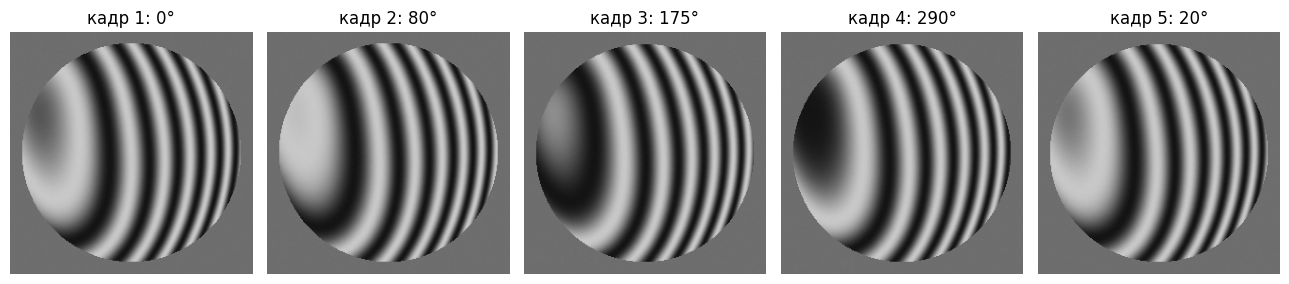

In [19]:
frames = psi_demo.make_frames(args, w)
fig, axes = plt.subplots(1, len(frames), figsize=(2.6 * len(frames), 2.8))
for n, (ax, frame) in enumerate(zip(axes, frames)):
    ax.imshow(frame, cmap="gray", vmin=0, vmax=255)
    ax.set_title("кадр %d: %g°" % (n + 1, args.shifts[n]))
    ax.axis("off")
plt.tight_layout()
fig.savefig(psi_demo.os.path.join(args.out, "frames.png"), dpi=90)
plt.show()

## Итог по режимам

- **ошибка сдвигов** — наибольшее отличие найденного сдвига кадра от настоящего;
- **ошибка карты** — СКО разницы карты DigitQt и заложенного фронта (поршень вычтен);
- **невязка / половины** — диагностика самой программы (лекция 6.5): она правды не знает.

In [20]:
header = "%-8s %12s %12s %12s %12s %10s %6s" % (
    "режим", "сдвиги, °", "наклон, волн", "карта RMS", "невязка", "половины", "знак")
print(header)
print("-" * len(header))
for mode, report, cmp, orders in rows:
    print("%-8s %12.3f %12s %12.5f %12.2f %10.3f %6s" % (
        mode, cmp["shift_err"],
        "%.4f" % cmp["tilt_err"] if "tilt_err" in cmp else "-",
        cmp["map_rms"],
        psi_demo.numbers(report["Fit residual"])[0],
        psi_demo.numbers(report["Halves disagree"])[0],
        "ПЕРЕВ." if cmp["sign_flipped"] else "ок"))

режим       сдвиги, ° наклон, волн    карта RMS      невязка   половины   знак
------------------------------------------------------------------------------
nominal        20.000            -      0.00229        11.19      0.036     ок
refine          0.010            -      0.00124         0.66      0.009     ок
tilt            0.080       0.0090      0.00182         0.68      0.685     ок


## Сдвиги: заложенные и найденные

Пунктир — номинальные (`n · step`), с них DigitQt начинает.

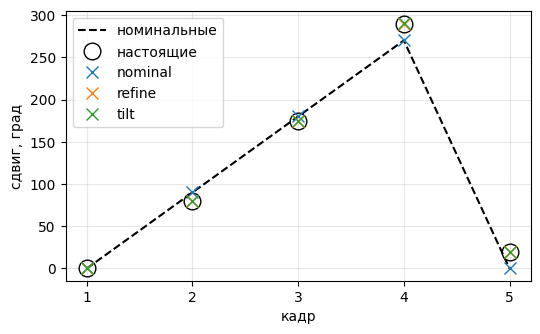

In [21]:
true_shifts = np.mod(np.array(args.shifts) - args.shifts[0], 360)
frames_idx = np.arange(1, len(true_shifts) + 1)
plt.figure(figsize=(6, 3.5))
plt.plot(frames_idx, np.mod(args.step * (frames_idx - 1), 360), "k--", label="номинальные")
plt.plot(frames_idx, true_shifts, "o", ms=12, mfc="none", color="k", label="настоящие")
for mode, report, cmp, orders in rows:
    plt.plot(frames_idx, psi_demo.numbers(report["Shifts, deg"]), "x", ms=9, label=mode)
plt.xticks(frames_idx)
plt.xlabel("кадр")
plt.ylabel("сдвиг, град")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(psi_demo.os.path.join(args.out, "shifts.png"), dpi=90)
plt.show()

## Аберрации: заложено и найдено на S5

Коэффициенты в волнах. Если знак карты перевёрнут (зеркальное решение), найденные сравниваются со знаком минус.

In [22]:
names = list(psi_demo.ABERRATIONS)
print("%-10s %9s" % ("терм", "заложено") + "".join("%11s" % m for m, *_ in rows))
for name in names:
    true = getattr(args, name)
    found = [cmp["s5"][name][1] for _, _, cmp, _ in rows]
    if true == 0 and all(abs(f) < 0.005 for f in found):
        continue  # не заложен и не найден
    print("%-10s %9.3f" % (name, true) + "".join("%11.3f" % f for f in found))
print("%-10s %9s" % ("ошибка", "") + "".join("%11.4f" % cmp["s5_err"] for _, _, cmp, _ in rows))

терм        заложено    nominal     refine       tilt
carrier_x      3.000      3.000      3.000      2.998
defocus        1.000      0.999      1.000      1.000
astig_x        0.300      0.300      0.300      0.300
astig_y        0.200      0.201      0.200      0.200
coma_x         0.300      0.301      0.300      0.300
coma_y        -0.200     -0.200     -0.200     -0.200
trefoil_x      0.150      0.150      0.150      0.150
trefoil_y      0.100      0.101      0.100      0.100
spherical      0.400      0.400      0.400      0.400
ошибка                   0.0008     0.0000     0.0025


## Карты и ошибки

Верхний ряд — карта DigitQt (порядки полосы), нижний — её отличие от заложенного фронта.
Рябь колец с **удвоенной** частотой полос — след неверных сдвигов (лекция 5).

Картинки и кадры серии: c:\Ilya\dev\cpp\qt\digit-qt\test_data\psi_synthetic\demo_everything


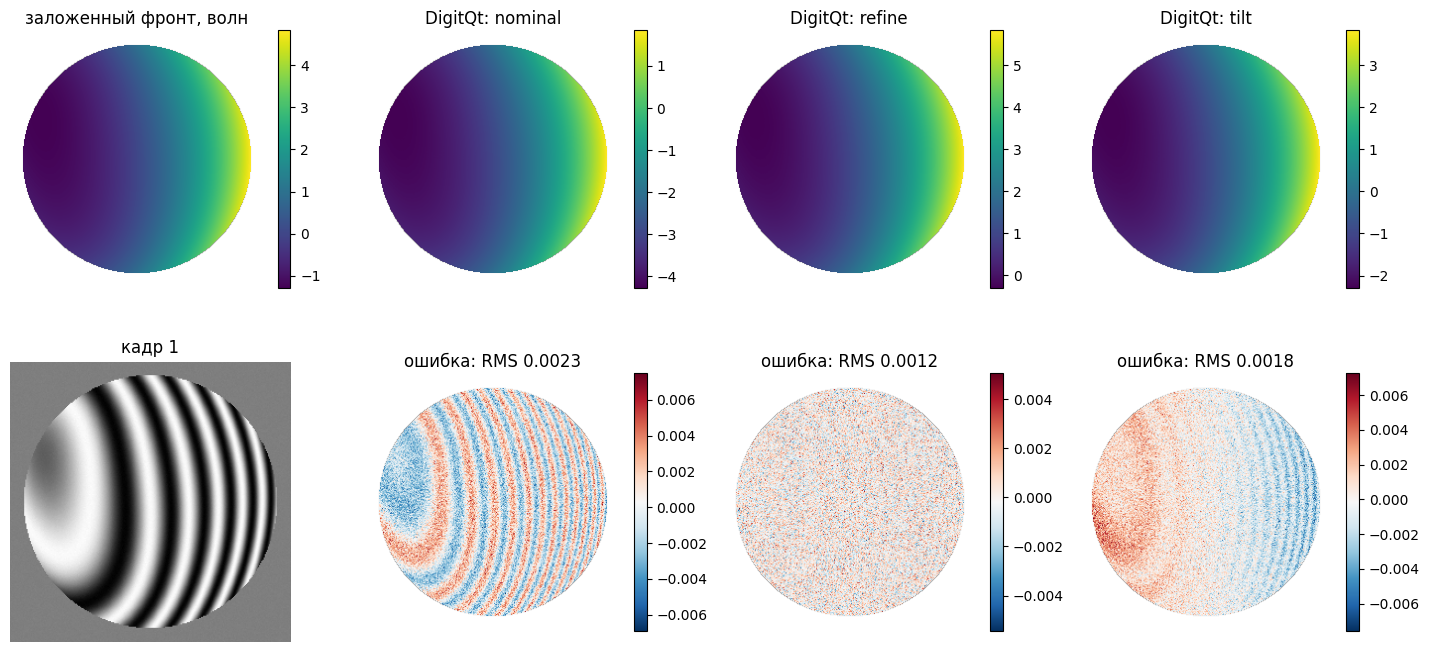

In [23]:
fig = psi_demo.plot(args, w, rows)
fig.savefig(psi_demo.os.path.join(args.out, "demo.png"), dpi=90)
print("Картинки и кадры серии:", args.out)
plt.show()